In [100]:
import matplotlib.pyplot as plt
import csv

In [101]:
X = []
y = []
with open('data.csv', 'r') as file:
    reader = csv.reader(file)
    header = next(reader)
    print(header)
    target_index = header.index('diagnosis')
    id_index = header.index('id')
    for row in reader:
        data = []
        for i in range(len(row)):
            if i != target_index and i!= id_index:
                data.append(float(row[i]))
        y.append(row[target_index])
        X.append(data)
print(len(X))
print(len(X[0]))

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', '']
569
30


In [102]:
def calculate_mean(values):
    total = 0
    for value in values:
        total += value
    return total / len(values)

In [103]:
def calculate_std(values, mean):
    squared_sum = 0
    for value in values:
        diff = value - mean
        squared_sum += diff * diff
    return (squared_sum / len(values)) ** 0.5


In [104]:
def fit_scalar(X):
    means = []
    stds = []

    for j in range(len(X[0])):
        col = []
        for i in range(len(X)):
            col.append(X[i][j])
        mean_col = calculate_mean(col)
        means.append(mean_col)
        stds.append(calculate_std(col, mean_col))

    return means, stds



In [105]:
def transform_data(X, means, stds):
    scaled_X = []
    for row in X:
        scaled_row = []
        for j in range(len(row)):
            scaled_value = (row[j] - means[j]) / stds[j]
            scaled_row.append(scaled_value)
        scaled_X.append(scaled_row)
    return scaled_X


In [106]:
import random

In [107]:
def stratified_train_test_split(X, y, test_ratio = 0.2):
    random.seed(42)
    class_indices = {}
    for i in range(len(y)):
        label = y[i]
        if label not in class_indices:
            class_indices[label] = []
        class_indices[label].append(i)
    train_indices = []
    test_indices = []
    for label in class_indices:
        indices = class_indices[label]
        random.shuffle(indices)
        test_size = round(len(indices) * test_ratio)
        test_indices.extend(indices[:test_size])
        train_indices.extend(indices[test_size:])
    random.shuffle(train_indices)
    random.shuffle(test_indices)
    X_train = []
    y_train = []
    X_test = []
    y_test = []
    for i in train_indices:
        X_train.append(X[i])
        y_train.append(y[i])
    for i in test_indices:
        X_test.append(X[i])
        y_test.append(y[i])
    return X_train, y_train, X_test, y_test

In [108]:
X_train, y_train, X_test, y_test = stratified_train_test_split(X, y)
print(len(X_train))
print(len(X_train[0]))
print(len(X_test))
print(len(X_test[0]))
print(len(y_train))
print(len(y_train[0]))
print(len(y_test))
print(len(y_test[0]))

456
30
113
30
456
1
113
1


In [109]:
means, stds = fit_scalar(X_train)
X_train_scaled = transform_data(X_train, means, stds)
X_test_scaled = transform_data(X_test, means, stds)

In [110]:
# Check the first feature
col = [row[0] for row in X_train_scaled]

print("Mean:", calculate_mean(col))
print("Std:", calculate_std(col, calculate_mean(col)))

Mean: -1.358927590338884e-15
Std: 1.0


In [111]:
import math
print(math.isclose(calculate_mean(col), 0, abs_tol = 1e-6))

True


In [112]:
print(len(X_train_scaled))
print(len(X_train_scaled[0]))

456
30


In [123]:
def calculate_covariance_matrix(X):
    X = np.array(X, dtype=float)
    n_samples = X.shape[0]
    cov_matrix = (X.T @ X) / (n_samples - 1)
    return cov_matrix

In [124]:
cov_matrix = calculate_covariance_matrix(X_train_scaled)
print(len(cov_matrix))
print(len(cov_matrix[0]))
for row in cov_matrix:
    print(row)

30
30
[ 1.0021978   0.30115098  0.99998613  0.99084365  0.18406854  0.51670771
  0.67521074  0.82671153  0.14760714 -0.2927079   0.66431694 -0.1031922
  0.66609179  0.74471449 -0.22834744  0.20489623  0.18016483  0.36580228
 -0.09424805 -0.04288334  0.97161256  0.2839398   0.9672913   0.94694636
  0.13727471  0.44191571  0.53920044  0.75905632  0.18925931  0.03611078]
[ 3.01150978e-01  1.00219780e+00  3.07925387e-01  2.99117324e-01
 -2.17264104e-02  2.37131711e-01  3.01040857e-01  2.86668013e-01
  7.73361943e-02 -6.09110676e-02  2.63771388e-01  4.06524692e-01
  2.73386767e-01  2.42723515e-01  1.34875685e-02  2.00467277e-01
  1.45889771e-01  1.70774718e-01 -7.96674605e-04  6.75332540e-02
  3.32228759e-01  9.14701063e-01  3.39629255e-01  3.23274063e-01
  9.89465731e-02  2.91411633e-01  3.11232440e-01  2.94952164e-01
  1.05447240e-01  1.48079964e-01]
[ 0.99998613  0.30792539  1.0021978   0.98959827  0.22093382  0.56830829
  0.71503856  0.85537318  0.18335507 -0.24116616  0.67503077 -0.091

In [125]:

def matrix_vector_multiply(A, v):
    result = []
    for i in range(len(A)):
        total = 0
        for j in range(len(v)):
            total += A[i][j] * v[j]
        result.append(total)
    return result


In [126]:
def dot_product(a, b):
    total = 0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

In [127]:
def vector_norm(v):
    total = 0

    for value in v:
        total += value * value

    return total ** 0.5

In [128]:
import numpy as np
def power_iteration(C, max_iter=10000, tol=1e-10):
    p = len(C)
    v = np.ones(p)
    v = v / vector_norm(v)
    for iteration in range(max_iter):
        new_v = C @ v
        norm = vector_norm(new_v)
        new_v = new_v / norm
        difference1 = vector_norm(new_v - v)
        difference2 = vector_norm(new_v + v)
        if min(difference1, difference2) < tol:
            v = new_v
            break
        v = new_v
    eigenvalue = v @ (C @ v)
    return eigenvalue, v

In [129]:
lambda1, v1 = power_iteration(cov_matrix)
print("PC1 eigenvalue:", lambda1)
print("PC1 eigenvector:")
print(v1)
print("Length of PC1 eigenvector:", vector_norm(v1))

PC1 eigenvalue: 13.319247448860612
PC1 eigenvector:
[0.21957982 0.10196953 0.22819404 0.22130745 0.14333643 0.23990482
 0.25731982 0.26083683 0.1361864  0.06790559 0.20168521 0.0220499
 0.20817036 0.20353325 0.01149332 0.17040374 0.15109163 0.18335713
 0.04609431 0.10241966 0.22750002 0.10477087 0.23628642 0.22488166
 0.12756624 0.21357356 0.22945788 0.25066514 0.12431834 0.1367924 ]
Length of PC1 eigenvector: 1.0


In [130]:
def deflation(C, eigenvalue, eigenvector):
    outer_product = np.outer(eigenvector, eigenvector)

    C_new = C - eigenvalue * outer_product

    return C_new

In [131]:

C_deflated = deflation(cov_matrix, lambda1, v1)

lambda2, v2 = power_iteration(C_deflated)

print("PC1 eigenvalue:", lambda1)
print("PC2 eigenvalue:", lambda2)

PC1 eigenvalue: 13.319247448860612
PC2 eigenvalue: 5.602522545086995


In [132]:
def explained_variance_ratio(eigenvalue, total_variance):
    return eigenvalue / total_variance

total_variance = 0

for i in range(len(X_train_scaled[0])):
    total_variance += cov_matrix[i][i]

evr1 = explained_variance_ratio(lambda1, total_variance)
evr2 = explained_variance_ratio(lambda2, total_variance)

print("PC1 explained variance:", round(evr1, 4))
print("PC2 explained variance:", round(evr2, 4))

print("Combined explained variance:",
      round(evr1 + evr2, 4))

print("Combined percentage:",
      round((evr1 + evr2) * 100, 2), "%")

PC1 explained variance: 0.443
PC2 explained variance: 0.1863
Combined explained variance: 0.6293
Combined percentage: 62.93 %


In [133]:
components = np.column_stack((v1, v2))
print("Components shape:", components.shape)

Components shape: (30, 2)


In [135]:
T = X_train_scaled @ components
print("Projected data shape:", T.shape)
print(np.round(T[:5], 3))

Projected data shape: (456, 2)
[[-0.656 -0.948]
 [-3.088 -2.213]
 [-2.912 -0.261]
 [-1.426 -1.833]
 [-2.361  0.47 ]]


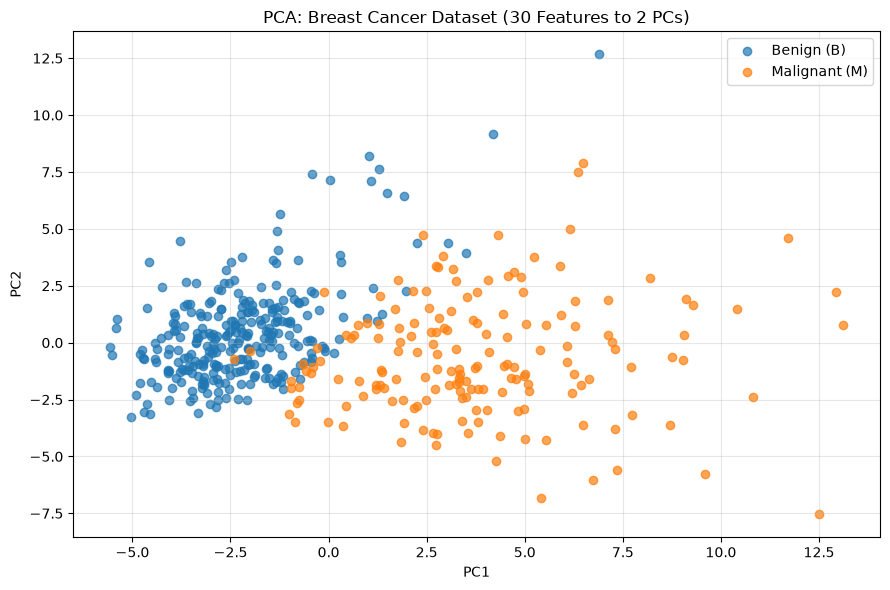

In [138]:
y_train = np.array(y_train)
benign = (y_train == "B")
malignant = (y_train == "M")
plt.figure(figsize=(9, 6))

plt.scatter(
    T[benign, 0],
    T[benign, 1],
    label="Benign (B)",
    alpha=0.7
)

plt.scatter(
    T[malignant, 0],
    T[malignant, 1],
    label="Malignant (M)",
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: Breast Cancer Dataset (30 Features to 2 PCs)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [139]:
print("Norm of v1:", vector_norm(v1))
print("Norm of v2:", vector_norm(v2))
print("Dot product of v1 and v2:", v1 @ v2)

print("Eigenvalue PC1:", lambda1)
print("Eigenvalue PC2:", lambda2)

print("Combined explained variance (%):",
      round((evr1 + evr2) * 100, 2))

Norm of v1: 1.0
Norm of v2: 1.0
Dot product of v1 and v2: -5.952068699022206e-11
Eigenvalue PC1: 13.319247448860612
Eigenvalue PC2: 5.602522545086995
Combined explained variance (%): 62.93


In [141]:
print("PC1 eigenvector error:",
      vector_norm(cov_matrix @ v1 - lambda1 * v1))

print("PC2 eigenvector error:",
      vector_norm(C_deflated @ v2 - lambda2 * v2))

PC1 eigenvector error: 3.334657405989229e-10
PC2 eigenvector error: 2.5735402535751127e-10
